# 01 · Load the data, check the masks, count, and the floor

README steps 1 and 3. Question: *can a U-Net outline polyps in colonoscopy images well
enough to help a doctor not miss one?* Before any model we check what the data looks
like and what the trivial answers score.

In [1]:
# Setup: works on Colab and on our own laptops.
import os, sys
if "google.colab" in sys.modules and not os.path.exists("src"):
    !git clone https://github.com/Chandana18G/kvasir-seg-polyp-segmentation
    %cd kvasir-seg-polyp-segmentation
if os.path.basename(os.getcwd()) in ("chandana", "dinesh"):
    os.chdir("..")                      # run everything from the project folder
if not os.path.exists("data/Kvasir-SEG/images"):
    !python scripts/download_data.py    # 46 MB from datasets.simula.no
sys.path.insert(0, "src")

import numpy as np
import matplotlib.pyplot as plt
from data import list_names, load_image, load_mask, load_resized, read_split
os.makedirs("results", exist_ok=True)

## 1 · How many images, and do the masks match?

In [2]:
names = list_names()
print("images:", len(names))

sizes = []
for name in names:
    image = load_image(name)
    mask = load_mask(name)
    assert image.shape[:2] == mask.shape, name   # mask and photo have the same size
    sizes.append(image.shape[:2])

heights = [h for h, w in sizes]
widths = [w for h, w in sizes]
print("width from", min(widths), "to", max(widths), "pixels")
print("height from", min(heights), "to", max(heights), "pixels")
print("different sizes:", len(set(sizes)))

images: 1000


width from 332 to 1920 pixels
height from 352 to 1072 pixels
different sizes: 333


## 2 · Are the masks really black and white?

The masks are saved as JPEG. JPEG blurs sharp edges a little, so we count how many
pixels are not exactly 0 or 255. `load_mask` turns everything above 127 into polyp.

In [3]:
from PIL import Image
not_pure = 0
total = 0
for name in names:
    path = os.path.join("data", "Kvasir-SEG", "masks", name + ".jpg")
    grey = np.array(Image.open(path).convert("L"))
    not_pure += np.sum((grey != 0) & (grey != 255))
    total += grey.size
print(f"pixels that are not exactly 0 or 255: {100 * not_pure / total:.2f} %")

pixels that are not exactly 0 or 255: 0.73 %


## 3 · How much of each image is polyp?

The "foreground share" p = polyp pixels / all pixels, per image. Every image has a
polyp, so p > 0 always.

images with no polyp pixel: 0
polyp share: mean 0.154, median 0.114, min 0.0047, max 0.812
images where the polyp is under 5 % of the picture: 200


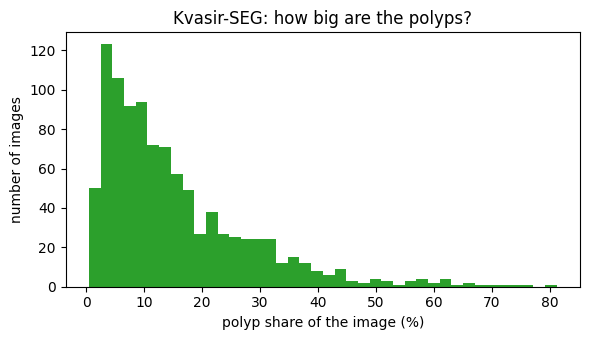

In [4]:
share = {}
for name in names:
    mask = load_mask(name)
    share[name] = mask.mean()

p = np.array(list(share.values()))
print(f"images with no polyp pixel: {np.sum(p == 0)}")
print(f"polyp share: mean {p.mean():.3f}, median {np.median(p):.3f}, "
      f"min {p.min():.4f}, max {p.max():.3f}")
print(f"images where the polyp is under 5 % of the picture: {np.sum(p < 0.05)}")

plt.figure(figsize=(6, 3.5))
plt.hist(p * 100, bins=40, color="tab:green")
plt.xlabel("polyp share of the image (%)")
plt.ylabel("number of images")
plt.title("Kvasir-SEG: how big are the polyps?")
plt.tight_layout()
plt.savefig("results/fig_polyp_share.png", dpi=150)
plt.show()

## 4 · The floor: what do trivial answers score?

Dice = 2 · |prediction ∩ truth| / (|prediction| + |truth|), per image, then averaged.

- **Always background** (predict "no polyp anywhere"): the overlap is 0, so Dice = 0 for every image.
- **Always polyp** (paint the whole image): overlap = truth, so Dice = 2p / (1 + p).

We show both on the validation and test images. Any real method must beat these.

In [5]:
def dice(prediction, truth):
    overlap = np.sum(prediction * truth)
    size_sum = prediction.sum() + truth.sum()
    return 2 * overlap / size_sum if size_sum > 0 else 1.0

for split in ["val", "test"]:
    split_names = read_split(split)
    all_background, all_polyp = [], []
    for name in split_names:
        truth = load_mask(name)
        all_background.append(dice(np.zeros_like(truth), truth))
        all_polyp.append(dice(np.ones_like(truth), truth))
    print(f"{split:5s} ({len(split_names)} images): "
          f"always background Dice {np.mean(all_background):.3f}, "
          f"always polyp Dice {np.mean(all_polyp):.3f} ± {np.std(all_polyp):.3f}")

val   (100 images): always background Dice 0.000, always polyp Dice 0.247 ± 0.169


test  (120 images): always background Dice 0.000, always polyp Dice 0.243 ± 0.184


## 5 · Shrink once to 256 × 256 and save

All later methods use the same small copies. The mask is shrunk with NEAREST so it stays
0/1. About 200 MB, saved in `data/` (not on GitHub).

In [6]:
images = np.zeros((len(names), 256, 256, 3), dtype=np.uint8)
masks = np.zeros((len(names), 256, 256), dtype=np.uint8)
for i, name in enumerate(names):
    images[i], masks[i] = load_resized(name, 256)
np.savez_compressed("data/kvasir_256.npz", names=np.array(names), images=images, masks=masks)
print("saved", images.shape, masks.shape)

saved (1000, 256, 256, 3) (1000, 256, 256)
